In [46]:
!pip install -q qiskit qiskit-aer matplotlib numpy tabulate

import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

simulator = AerSimulator()

In [47]:
def build_radar_line_circuit(has_ship: bool, theta: float = np.pi / 3) -> QuantumCircuit:
    qc = QuantumCircuit(2, 2)
    qc.ry(theta, 0)
    if has_ship:
        qc.cx(0, 1)
    qc.ry(-theta, 0)
    qc.measure([0, 1], [0, 1])
    return qc

In [48]:
class BattleshipBoard:
    def __init__(self, size: int = 4):
        self.size = size
        self.grid = np.zeros((size, size), dtype=int)
        self.ships = []

    def place_ship(self, row: int, col: int, length: int, horizontal: bool = True):
        coords = []
        for i in range(length):
            r = row if horizontal else row + i
            c = col + i if horizontal else col
            if r >= self.size or c >= self.size or self.grid[r, c] == 1:
                raise ValueError("Invalid ship placement")
            self.grid[r, c] = 1
            coords.append((r, c))
        self.ships.append(coords)

    def row_has_ship(self, r: int) -> bool:
        return np.any(self.grid[r, :] == 1)

    def col_has_ship(self, c: int) -> bool:
        return np.any(self.grid[:, c] == 1)

    def display(self, overlay_cells=None, overlay_symbol=" * "):
        symbols = {0: " ~ ", 1: " S "}
        header = "   " + " ".join([f"C{c}" for c in range(self.size)])
        print(header)
        for r in range(self.size):
            row_str = f"R{r} "
            for c in range(self.size):
                if overlay_cells and (r, c) in overlay_cells:
                    row_str += overlay_symbol
                else:
                    row_str += symbols[self.grid[r, c]]
            print(row_str)
        print()


def run_classical_baseline(board: BattleshipBoard):
    measurements = board.size * board.size
    hits = int(np.sum(board.grid))
    misses = measurements - hits
    return {
        "strategy": "Classical Brute-Force",
        "measurements": measurements,
        "detections": 0,
        "explosions": hits,
        "misses": misses,
        "if_score": 0.0,
        "candidates": [(r, c) for r in range(board.size) for c in range(board.size) if board.grid[r, c] == 1]
    }

In [49]:
def run_quantum_radar(board: BattleshipBoard, theta: float = np.pi / 3, shots: int = 5000, noise_model: NoiseModel = None):
    backend = AerSimulator(noise_model=noise_model) if noise_model else simulator
    total_measurements = board.size * 2
    total_det_shots = 0
    total_exp_shots = 0
    flagged_rows = []
    flagged_cols = []

    for r in range(board.size):
        has_ship = board.row_has_ship(r)
        qc = build_radar_line_circuit(has_ship, theta=theta)
        counts = backend.run(transpile(qc, backend), shots=shots).result().get_counts()

        exp_count = sum(v for k, v in counts.items() if k[0] == '1')
        det_count = sum(v for k, v in counts.items() if k == '01')

        if has_ship:
            total_exp_shots += exp_count
            total_det_shots += det_count

        if exp_count > (0.10 * shots) or det_count > (0.10 * shots):
            flagged_rows.append(r)

    for c in range(board.size):
        has_ship = board.col_has_ship(c)
        qc = build_radar_line_circuit(has_ship, theta=theta)
        counts = backend.run(transpile(qc, backend), shots=shots).result().get_counts()

        exp_count = sum(v for k, v in counts.items() if k[0] == '1')
        det_count = sum(v for k, v in counts.items() if k == '01')

        if has_ship:
            total_exp_shots += exp_count
            total_det_shots += det_count

        if exp_count > (0.10 * shots) or det_count > (0.10 * shots):
            flagged_cols.append(c)

    candidates = [(r, c) for r in flagged_rows for c in flagged_cols]
    if_score = total_det_shots / total_exp_shots if total_exp_shots > 0 else 0.0
    efficiency = (board.size * board.size) / total_measurements
    battleship_score = if_score * efficiency

    return {
        "strategy": f"Quantum Radar (theta={theta:.2f} rad)",
        "measurements": total_measurements,
        "detections": total_det_shots,
        "explosions": total_exp_shots,
        "if_score": if_score,
        "efficiency": efficiency,
        "battleship_score": battleship_score,
        "candidates": candidates
    }

In [50]:
board = BattleshipBoard(size=4)
board.place_ship(row=1, col=1, length=1, horizontal=True)
board.place_ship(row=3, col=2, length=2, horizontal=True)

print("--- Ground Truth Fleet Layout (S = Ship, ~ = Ocean) ---")
board.display()

classical_res = run_classical_baseline(board)
q_res_pi2 = run_quantum_radar(board, theta=np.pi / 2, shots=5000)
q_res_pi3 = run_quantum_radar(board, theta=np.pi / 3, shots=5000)

print("--- Quantum Radar Pinpointed Fleet (* = Detected Candidate) ---")
board.display(overlay_cells=q_res_pi3["candidates"], overlay_symbol=" * ")

table_data = [
    [
        classical_res["strategy"],
        classical_res["measurements"],
        classical_res["detections"],
        classical_res["explosions"],
        f"{classical_res['if_score']:.2f}",
        "1.0x",
        "0.00"
    ],
    [
        q_res_pi2["strategy"],
        q_res_pi2["measurements"],
        q_res_pi2["detections"],
        q_res_pi2["explosions"],
        f"{q_res_pi2['if_score']:.2f}",
        f"{q_res_pi2['efficiency']:.1f}x",
        f"{q_res_pi2['battleship_score']:.2f}"
    ],
    [
        q_res_pi3["strategy"],
        q_res_pi3["measurements"],
        q_res_pi3["detections"],
        q_res_pi3["explosions"],
        f"{q_res_pi3['if_score']:.2f}",
        f"{q_res_pi3['efficiency']:.1f}x",
        f"{q_res_pi3['battleship_score']:.2f}"
    ]
]

headers = ["Strategy", "Queries", "Safe Detections", "Hits (Explosions)", "IF Score", "Efficiency Gain", "Battleship Score"]
print(tabulate(table_data, headers=headers, tablefmt="github"))

--- Ground Truth Fleet Layout (S = Ship, ~ = Ocean) ---
   C0 C1 C2 C3
R0  ~  ~  ~  ~ 
R1  ~  S  ~  ~ 
R2  ~  ~  ~  ~ 
R3  ~  ~  S  S 

--- Quantum Radar Pinpointed Fleet (* = Detected Candidate) ---
   C0 C1 C2 C3
R0  ~  ~  ~  ~ 
R1  ~  *  *  * 
R2  ~  ~  ~  ~ 
R3  ~  *  *  * 

| Strategy                       |   Queries |   Safe Detections |   Hits (Explosions) |   IF Score | Efficiency Gain   |   Battleship Score |
|--------------------------------|-----------|-------------------|---------------------|------------|-------------------|--------------------|
| Classical Brute-Force          |        16 |                 0 |                   3 |       0    | 1.0x              |               0    |
| Quantum Radar (theta=1.57 rad) |         8 |              6379 |               12407 |       0.51 | 2.0x              |               1.03 |
| Quantum Radar (theta=1.05 rad) |         8 |              4600 |                6273 |       0.73 | 2.0x              |               1.47 |


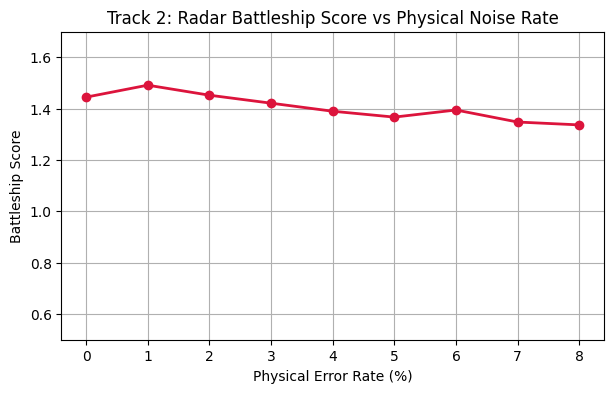

In [51]:
error_rates = np.linspace(0.0, 0.08, 9)
noise_scores = []

for err in error_rates:
    nm = None
    if err > 0:
        nm = NoiseModel()
        err_1q = depolarizing_error(err, 1)
        err_2q = depolarizing_error(err * 2, 2)
        ro_err = ReadoutError([[1 - err, err], [err, 1 - err]])
        nm.add_all_qubit_quantum_error(err_1q, ['ry'])
        nm.add_all_qubit_quantum_error(err_2q, ['cx'])
        nm.add_all_qubit_readout_error(ro_err)

    res = run_quantum_radar(board, theta=np.pi / 3, shots=5000, noise_model=nm)
    noise_scores.append(res["battleship_score"])

plt.figure(figsize=(7, 4))
plt.plot(error_rates * 100, noise_scores, marker='o', color='crimson', lw=2)
plt.title("Track 2: Radar Battleship Score vs Physical Noise Rate")
plt.xlabel("Physical Error Rate (%)")
plt.ylabel("Battleship Score")
plt.ylim(bottom=0.5, top=1.7)
plt.grid(True)
plt.show()

| Board Size   |   Classical Queries (N^2) |   Quantum Queries (2N) | Efficiency Multiplier   |
|--------------|---------------------------|------------------------|-------------------------|
| 4x4          |                        16 |                      8 | 2.0x                    |
| 6x6          |                        36 |                     12 | 3.0x                    |
| 8x8          |                        64 |                     16 | 4.0x                    |
| 10x10        |                       100 |                     20 | 5.0x                    |


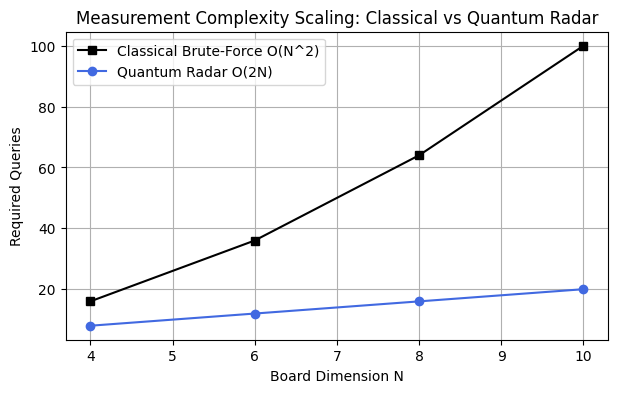

In [52]:
board_sizes = [4, 6, 8, 10]
classical_measurements = [N * N for N in board_sizes]
quantum_measurements = [2 * N for N in board_sizes]
efficiency_multipliers = [N / 2 for N in board_sizes]

scale_table = [
    [f"{N}x{N}", c_m, q_m, f"{eff:.1f}x"]
    for N, c_m, q_m, eff in zip(board_sizes, classical_measurements, quantum_measurements, efficiency_multipliers)
]

print(tabulate(scale_table, headers=["Board Size", "Classical Queries (N^2)", "Quantum Queries (2N)", "Efficiency Multiplier"], tablefmt="github"))

plt.figure(figsize=(7, 4))
plt.plot(board_sizes, classical_measurements, marker='s', label="Classical Brute-Force O(N^2)", color='black')
plt.plot(board_sizes, quantum_measurements, marker='o', label="Quantum Radar O(2N)", color='royalblue')
plt.title("Measurement Complexity Scaling: Classical vs Quantum Radar")
plt.xlabel("Board Dimension N")
plt.ylabel("Required Queries")
plt.legend()
plt.grid(True)
plt.show()

| Board Size   |   Classical Queries (N^2) |   Quantum Queries (2N) | Efficiency Multiplier   |
|--------------|---------------------------|------------------------|-------------------------|
| 4x4          |                        16 |                      8 | 2.0x                    |
| 6x6          |                        36 |                     12 | 3.0x                    |
| 8x8          |                        64 |                     16 | 4.0x                    |
| 10x10        |                       100 |                     20 | 5.0x                    |


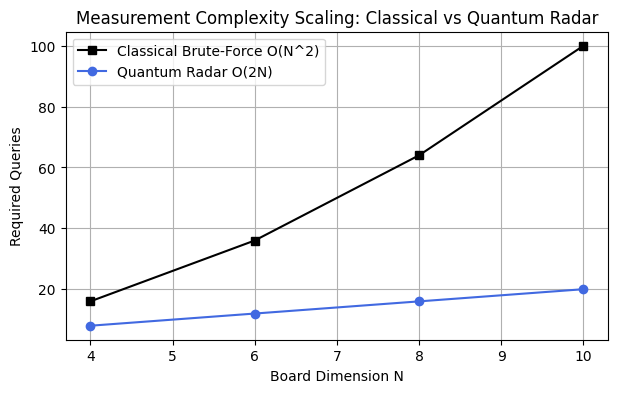

In [42]:
board_sizes = [4, 6, 8, 10]
classical_measurements = [N * N for N in board_sizes]
quantum_measurements = [2 * N for N in board_sizes]
efficiency_multipliers = [N / 2 for N in board_sizes]

scale_table = [
    [f"{N}x{N}", c_m, q_m, f"{eff:.1f}x"]
    for N, c_m, q_m, eff in zip(board_sizes, classical_measurements, quantum_measurements, efficiency_multipliers)
]

print(tabulate(scale_table, headers=["Board Size", "Classical Queries (N^2)", "Quantum Queries (2N)", "Efficiency Multiplier"], tablefmt="github"))

plt.figure(figsize=(7, 4))
plt.plot(board_sizes, classical_measurements, marker='s', label="Classical Brute-Force O(N^2)", color='black')
plt.plot(board_sizes, quantum_measurements, marker='o', label="Quantum Radar O(2N)", color='royalblue')
plt.title("Measurement Complexity Scaling: Classical vs Quantum Radar")
plt.xlabel("Board Dimension N")
plt.ylabel("Required Queries")
plt.legend()
plt.grid(True)
plt.show()